### Insertion Sort

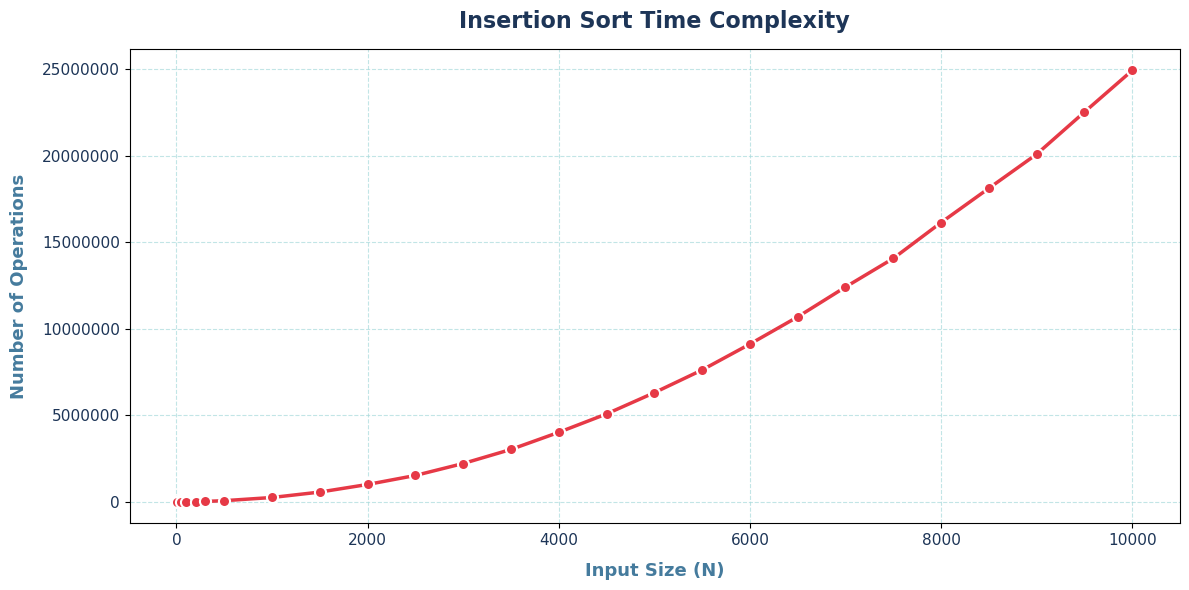

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

with open("unsorted_arrays.txt") as file:
    arrays = [[int(num) for num in line.split(" ")] for line in file.readlines()]
    array_size = [len(a) for a in arrays]
    operations_array = []
    sorted_array = []

    for a in arrays:
        operations = 0
        for i in range(1,len(a)):
            operations += 1
            j = i
            while(j > 0 and a[j] < a[j-1]):
                a[j],a[j-1] = a[j-1],a[j]
                j -= 1
                operations += 1
        sorted_array.append(a)
        operations_array.append(operations)

plt.figure(figsize=(12,6))
sns.lineplot(
    x=array_size, 
    y=operations_array, 
    color="#e63946",          
    linewidth=2.5,             
    marker="o",                
    markersize=8,              
    markeredgecolor="#ffffff", 
    markeredgewidth=1.5
)

plt.title("Insertion Sort Time Complexity",fontsize=16, fontweight='bold', pad=15, color="#1d3557")
plt.xlabel("Input Size (N)", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.ylabel("Number of Operations", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.xticks(fontsize=11, color="#1d3557")
plt.yticks(fontsize=11, color="#1d3557")
plt.grid(True, linestyle='--', alpha=0.7, color="#a8dadc")
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

### Count Sort


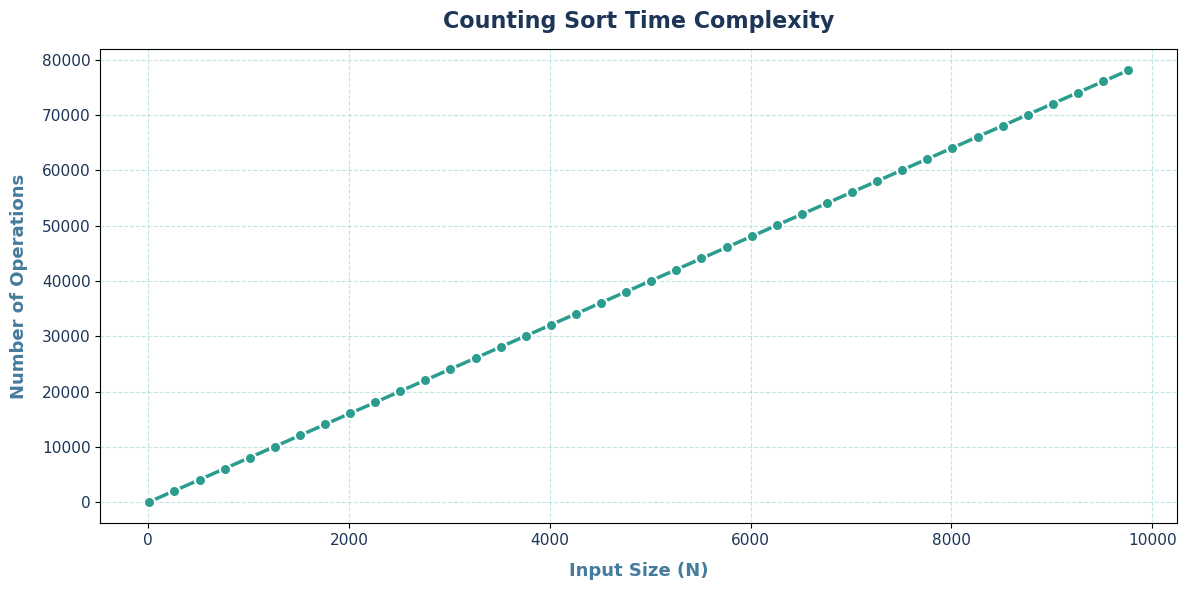

In [7]:
import random
import matplotlib.pyplot as plt
import seaborn as sns

arrays = []
array_sizes = list(range(10, 10001, 250)) 

for n in array_sizes:
    k_limit = 2 * n 
    a = [random.randint(1, k_limit) for _ in range(n)]
    arrays.append(a)

operations_array = []

for a in arrays:
    ops = 0
    n = len(a)
    k = max(a)  
    
    ops += n                           
    
    freq = [0 for x in range(0, k + 1)]
    ops += len(freq)                    
    
    for i in range(n):
        freq[a[i]] += 1
        ops += 1                        
        
    for i in range(1, len(freq)):
        freq[i] += freq[i-1]
        ops += 1                       
        
    final_array = [0] * n
    ops += n                            
    
    for i in range(n-1, -1, -1):
        target_index = freq[a[i]] - 1 
        final_array[target_index] = a[i]
        freq[a[i]] -= 1
        ops += 1                      
        
    operations_array.append(ops)

plt.figure(figsize=(12, 6))
sns.lineplot(
    x=array_sizes, 
    y=operations_array, 
    color="#2a9d8f",          
    linewidth=2.5,             
    marker="o",                
    markersize=8,              
    markeredgecolor="#ffffff", 
    markeredgewidth=1.5
)

plt.title("Counting Sort Time Complexity", fontsize=16, fontweight='bold', pad=15, color="#1d3557")
plt.xlabel("Input Size (N)", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.ylabel("Number of Operations", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.xticks(fontsize=11, color="#1d3557")
plt.yticks(fontsize=11, color="#1d3557")
plt.grid(True, linestyle='--', alpha=0.7, color="#a8dadc")
plt.tight_layout()
plt.show()

### Radix Sort

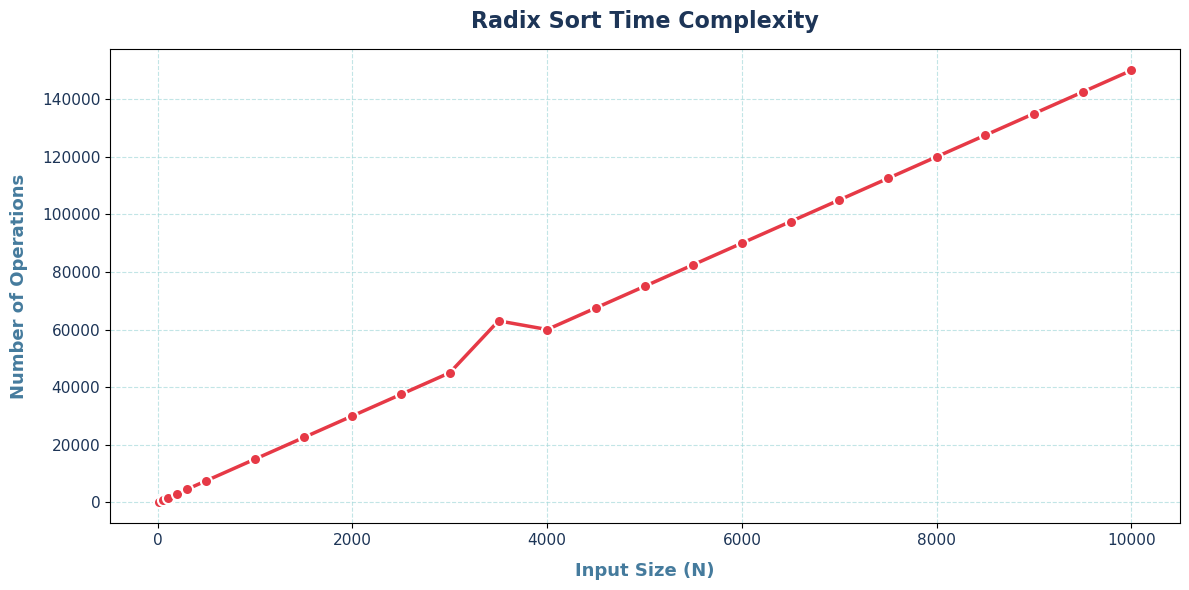

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

def count_sort(arr, exp):
    operations = 0

    n = len(arr)
    output = [0] * n
    count = [0] * 10

    for num in arr:
        digit = (num // exp) % 10
        count[digit] += 1
        operations += 1

    for i in range(1, 10):
        count[i] += count[i - 1]
        operations += 1

    for i in range(n - 1, -1, -1):
        digit = (arr[i] // exp) % 10
        output[count[digit] - 1] = arr[i]
        count[digit] -= 1
        operations += 1

    for i in range(n):
        arr[i] = output[i]
        operations += 1

    return operations


def radix_sort(arr):
    operations = 0

    maximum = max(arr)
    exp = 1

    while maximum // exp > 0:
        operations += count_sort(arr, exp)
        exp *= 10
        operations += 1

    return operations


with open("unsorted_arrays.txt") as file:
    arrays = [[int(num) for num in line.split()] for line in file.readlines()]

array_size = []
operations_array = []

for arr in arrays:
    temp = arr.copy()

    array_size.append(len(temp))
    operations = radix_sort(temp)
    operations_array.append(operations)

plt.figure(figsize=(12, 6))
sns.lineplot(
    x=array_size,
    y=operations_array,
    color="#e63946",
    linewidth=2.5,
    marker="o",
    markersize=8,
    markeredgecolor="#ffffff",
    markeredgewidth=1.5
)

plt.title("Radix Sort Time Complexity", fontsize=16, fontweight='bold', pad=15, color="#1d3557")
plt.xlabel("Input Size (N)", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.ylabel("Number of Operations", fontsize=13, fontweight='600', color="#457b9d", labelpad=10)
plt.xticks(fontsize=11, color="#1d3557")
plt.yticks(fontsize=11, color="#1d3557")
plt.grid(True, linestyle='--', alpha=0.7, color="#a8dadc")
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

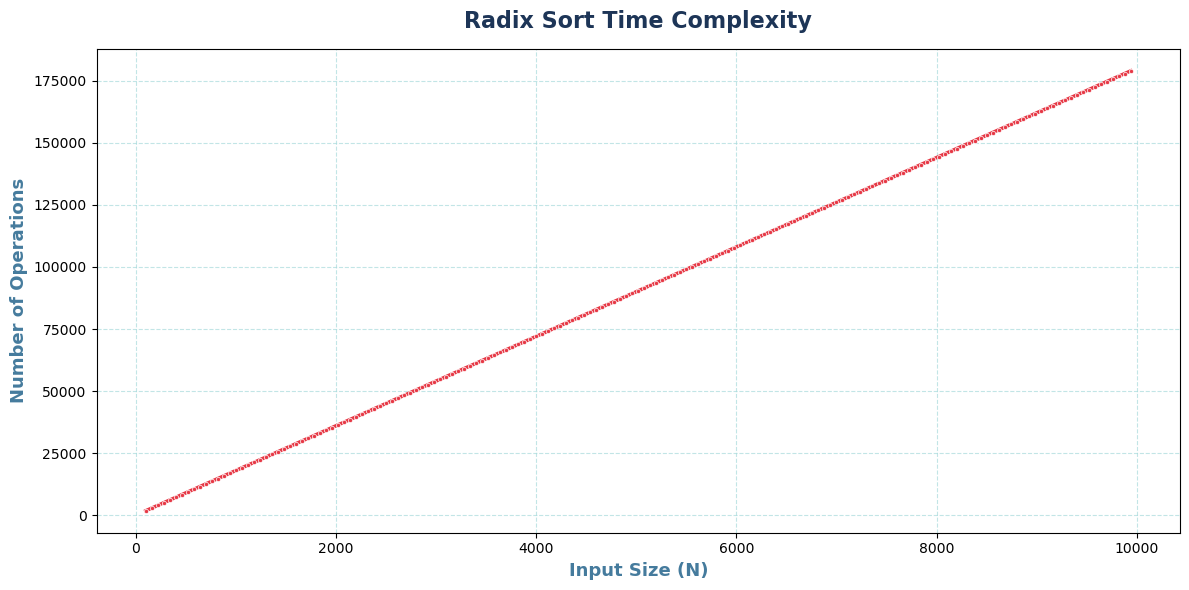

In [6]:
import random
import matplotlib.pyplot as plt
import seaborn as sns

def count_sort(arr, exp):
    operations = 0

    n = len(arr)
    output = [0] * n
    count = [0] * 10

    for num in arr:
        digit = (num // exp) % 10
        count[digit] += 1
        operations += 1

    for i in range(1, 10):
        count[i] += count[i - 1]
        operations += 1

    for i in range(n - 1, -1, -1):
        digit = (arr[i] // exp) % 10
        output[count[digit] - 1] = arr[i]
        count[digit] -= 1
        operations += 1

    for i in range(n):
        arr[i] = output[i]
        operations += 1

    return operations


def radix_sort(arr):
    operations = 0
    maximum = max(arr)
    exp = 1

    while maximum // exp > 0:
        operations += count_sort(arr, exp)
        exp *= 10
        operations += 1

    return operations


array_sizes = list(range(100, 10000, 60))
operations_array = []

for size in array_sizes:
    arr = [random.randint(0, 1_000_000) for _ in range(size)]
    operations = radix_sort(arr)
    operations_array.append(operations)

plt.figure(figsize=(12, 6))
sns.lineplot(
    x=array_sizes,
    y=operations_array,
    color="#e63946",
    linewidth=2.5,
    marker="o",
    markersize=3,
    markeredgecolor="#ffffff",
    markeredgewidth=0.5
)

plt.title("Radix Sort Time Complexity", fontsize=16, fontweight='bold', pad=15, color="#1d3557")
plt.xlabel("Input Size (N)", fontsize=13, fontweight='600', color="#457b9d")
plt.ylabel("Number of Operations", fontsize=13, fontweight='600', color="#457b9d")
plt.grid(True, linestyle='--', alpha=0.7, color="#a8dadc")
plt.ticklabel_format(style='plain', axis='both')
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

df = pd.DataFrame({
    "Input Size": array_sizes,
    "Number of Operations": operations_array
})

print(df)

df.to_csv("radix_sort_operations.csv", index=False)

     Input Size  Number of Operations
0           100                  1860
1           160                  2940
2           220                  4020
3           280                  5100
4           340                  6180
..          ...                   ...
160        9700                174660
161        9760                175740
162        9820                176820
163        9880                177900
164        9940                178980

[165 rows x 2 columns]


In [8]:
df

,Input Size,Number of Operations
0,100,1860
1,160,2940
2,220,4020
3,280,5100
4,340,6180
...,...,...
160,9700,174660
161,9760,175740
162,9820,176820
163,9880,177900
